# ¿Dónde vivirá la gente en 2100?

**Capítulo del curso:** Visualización de datos (Open-Ended Project 3)

Gapminder divide el mundo en cuatro regiones: África, Asia, Europa y América. Comparo cuántos miles de millones
de personas tiene cada una en 2000 y en 2100 (proyección) y cómo cambia desde 1800.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = Path("figuras")
FIG.mkdir(exist_ok=True)

In [2]:
indicadores = pd.read_csv("datos/world-indicators.csv", encoding="utf-8-sig")
NOMBRES = {"africa": "África", "asia": "Asia", "europe": "Europa", "americas": "América"}
COLORES = {"África": "#c8553d", "Asia": "#1f4e79", "Europa": "#5c8ca8", "América": "#e0a458"}

regiones = indicadores.query("region != 'world'").copy()
regiones["region"] = regiones["region"].map(NOMBRES)
regiones["pop_billions"] = (regiones["population"] / 1e9).round()
regiones.head()

,year,region,population,life_expectancy,child_mortality,babies_per_woman,income_per_person,pop_billions
0,1800,África,81209567,30.091575,443.51,6.58,437.699298,0.0
1,1801,África,81313551,30.016479,443.47,6.58,437.322912,0.0
2,1802,África,81418900,30.019117,443.44,6.58,436.949999,0.0
3,1803,África,81525621,30.099188,443.41,6.58,436.501460,0.0
4,1804,África,81633731,30.101720,443.37,6.58,436.033849,0.0


## Barras horizontales: 2000 frente a 2100

Cada bloque es mil millones de personas, redondeado.

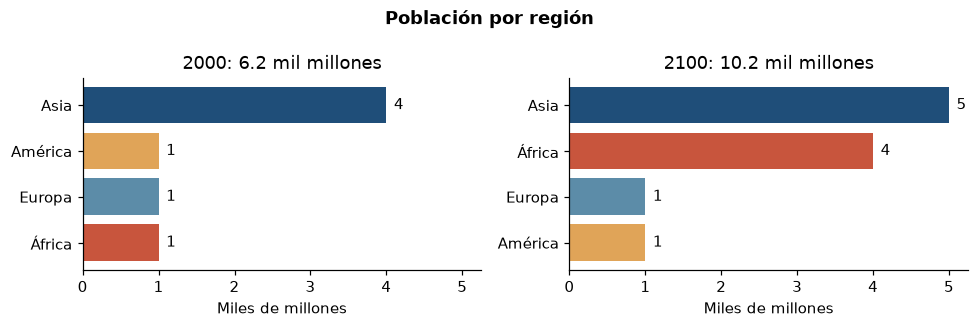

In [3]:
fig, ejes = plt.subplots(1, 2, figsize=(9, 3), sharex=True)
for ax, año in zip(ejes, [2000, 2100]):
    d = regiones[regiones["year"] == año].sort_values("pop_billions")
    ax.barh(d["region"], d["pop_billions"], color=[COLORES[r] for r in d["region"]])
    for y, valor in enumerate(d["pop_billions"]):
        ax.text(valor + 0.1, y, f"{valor:.0f}", va="center")
    total = indicadores.query("region == 'world' and year == @año")["population"].iloc[0] / 1e9
    ax.set_title(f"{año}: {total:.1f} mil millones")
    ax.set_xlabel("Miles de millones")
fig.suptitle("Población por región", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "barras-2000-2100.png", bbox_inches="tight")
plt.show()

## Línea de 1800 a 2100

Etiqueto cada línea al final en vez de usar leyenda, para leerla de un vistazo.

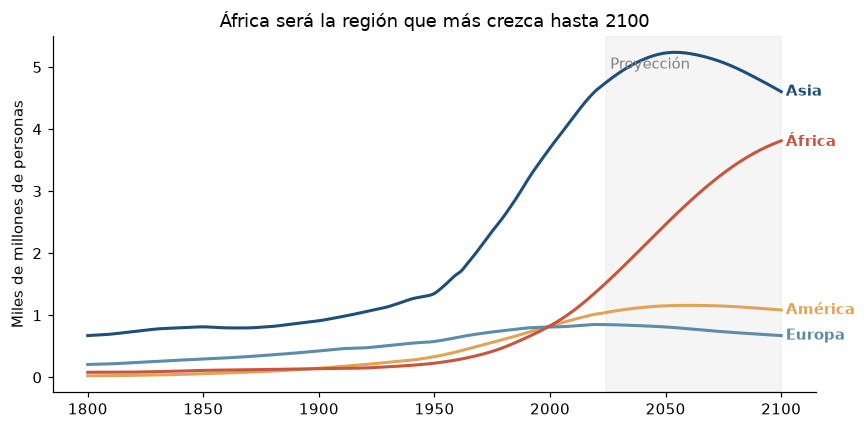

In [4]:
pivot = regiones.pivot(index="year", columns="region", values="population") / 1e9

fig, ax = plt.subplots(figsize=(8, 4))
for region in pivot.columns:
    ax.plot(pivot.index, pivot[region], color=COLORES[region], lw=2)
    ax.text(2102, pivot[region].iloc[-1], region, va="center", color=COLORES[region], fontweight="bold")
ax.axvspan(2024, 2100, color="grey", alpha=0.08)
ax.text(2026, pivot.max().max() * 0.95, "Proyección", color="grey")
ax.set_ylabel("Miles de millones de personas")
ax.set_title("África será la región que más crezca hasta 2100")
fig.tight_layout()
fig.savefig(FIG / "poblacion-1800-2100.png", bbox_inches="tight")
plt.show()

## Extra: menos hijos y más años de vida

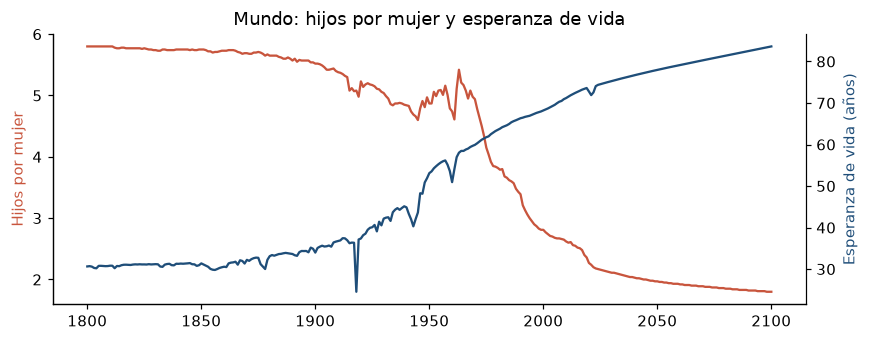

,year,life_expectancy,babies_per_woman,child_mortality
1354,1950,53.1,4.9,247.0
1427,2023,74.1,2.2,35.0
1504,2100,83.6,1.8,11.0


In [5]:
mundo = indicadores.query("region == 'world'")
fig, ax1 = plt.subplots(figsize=(8, 3.2))
ax1.plot(mundo["year"], mundo["babies_per_woman"], color="#c8553d")
ax1.set_ylabel("Hijos por mujer", color="#c8553d")
ax2 = ax1.twinx()
ax2.plot(mundo["year"], mundo["life_expectancy"], color="#1f4e79")
ax2.set_ylabel("Esperanza de vida (años)", color="#1f4e79")
ax2.spines["right"].set_visible(True)
ax1.set_title("Mundo: hijos por mujer y esperanza de vida")
fig.tight_layout()
fig.savefig(FIG / "hijos-y-esperanza.png", bbox_inches="tight")
plt.show()
mundo[mundo["year"].isin([1950, 2023, 2100])][["year", "life_expectancy", "babies_per_woman", "child_mortality"]].round(1)

## Conclusiones

- En 2000 éramos unos 6 mil millones: Asia tenía 4 bloques y África, Europa y América, 1 cada una.
- En 2100 la proyección llega a unos 10 mil millones: Asia sigue con 5 bloques, pero **África pasa a 4**.
  Europa es la única que baja (de 0,81 a 0,67 mil millones).
- La línea muestra el cruce: hacia el final del siglo África casi alcanza a Asia.
- El mundo pasa de 4,9 hijos por mujer en 1950 a 2,2 en 2023 (y 1,8 proyectado en 2100), mientras la esperanza de
  vida sube de 53 a 74 años. Por eso la población sigue creciendo, aunque cada vez más despacio.